# Mieux modele avec transcriptions:

Modele qu'il connait déjà des emotions (j-hartmann).




1. Charger les données

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
from google.colab import drive
from datasets import Dataset

drive.mount('/content/drive')
BASE_DIR = Path('/content/drive/MyDrive/Projet Multimedia')

EMOTION_LABELS = ['amusement', 'awe', 'contentment', 'excitement',
                  'anger', 'disgust', 'fear', 'sadness']
label2id = {l: i for i, l in enumerate(EMOTION_LABELS)}
id2label = {i: l for l, i in label2id.items()}

df = pd.read_csv(BASE_DIR / 'movie/dataset.csv')

# Transcriptions vides : NaN, "" ou uniquement des espaces, ou clip sans parole détectée
df['transcript'] = df['transcript'].fillna('').astype(str)
df['has_text'] = df['transcript'].str.strip().ne('') & df['has_speech'].astype(bool)

# Train, dev et test : uniquement les clips avec texte
train_df = df[(df['split'] == 'train') & df['has_text']].reset_index(drop=True)
dev_df   = df[(df['split'] == 'dev')   & df['has_text']].reset_index(drop=True)
test_df  = df[(df['split'] == 'test')   & df['has_text']].reset_index(drop=True)

print("Clips avec texte / total :")
for s in ['train', 'dev', 'test']:
    sub = df[df['split'] == s]
    print(f"  {s:5s} : {sub['has_text'].sum()} / {len(sub)}  ({(~sub['has_text']).sum()} vides)")

cols = ['transcript', 'label']
train_ds    = Dataset.from_pandas(train_df[cols])
dev_ds      = Dataset.from_pandas(dev_df[cols])
test_ds     = Dataset.from_pandas(test_df[cols])

Mounted at /content/drive
Clips avec texte / total :
  train : 1411 / 2208  (797 vides)
  dev   : 281 / 442  (161 vides)
  test  : 257 / 439  (182 vides)


2. Inspectioner données

In [3]:
print(train_df['label'].value_counts(normalize=True).sort_index(), "\n")
print("Nombre de mots par transcription (clips avec texte) :")
print(train_df['transcript'].str.split().str.len().describe())

label
0    0.079376
1    0.090716
2    0.134656
3    0.138200
4    0.243090
5    0.119064
6    0.093551
7    0.101347
Name: proportion, dtype: float64 

Nombre de mots par transcription (clips avec texte) :
count    1411.000000
mean       16.916371
std        13.398003
min         1.000000
25%         8.000000
50%        13.000000
75%        22.000000
max       102.000000
Name: transcript, dtype: float64


3. Tokenisation

In [4]:
from transformers import AutoTokenizer

MODEL_NAME = 'j-hartmann/emotion-english-distilroberta-base'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_fn(batch):
    texts = [str(text) if text is not None else "" for text in batch['transcript']]
    return tokenizer(texts, truncation=True, max_length=128)

train_tok  = train_ds.map(tokenize_fn, batched=True, remove_columns=['transcript'])
dev_tok    = dev_ds.map(tokenize_fn, batched=True, remove_columns=['transcript'])
test_tok   = test_ds.map(tokenize_fn, batched=True, remove_columns=['transcript'])

print(train_tok[0])
print(tokenizer.decode(train_tok[0]['input_ids']))

config.json:   0%|          | 0.00/1.00k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Map:   0%|          | 0/1411 [00:00<?, ? examples/s]

Map:   0%|          | 0/281 [00:00<?, ? examples/s]

Map:   0%|          | 0/257 [00:00<?, ? examples/s]

{'label': 2, 'input_ids': [0, 100, 437, 2997, 7, 14, 6429, 4, 221, 35830, 7, 972, 47, 4, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}
<s>I'm married to that lady. Pleased to meet you.</s>


4. Metriques et entrainement

In [5]:
pip install evaluate

In [6]:
from transformers import (AutoModelForSequenceClassification, DataCollatorWithPadding,
                          Trainer, TrainingArguments)
from sklearn.utils.class_weight import compute_class_weight
import torch, numpy as np

train_labels = train_df['label'].values
weights = compute_class_weight('balanced', classes=np.arange(8), y=train_labels)
weights = torch.tensor(weights, dtype=torch.float)
print(dict(zip(EMOTION_LABELS, weights.numpy().round(2))))

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=weights.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

{'amusement': np.float32(1.57), 'awe': np.float32(1.38), 'contentment': np.float32(0.93), 'excitement': np.float32(0.9), 'anger': np.float32(0.51), 'disgust': np.float32(1.05), 'fear': np.float32(1.34), 'sadness': np.float32(1.23)}


In [7]:
import torch
import evaluate
from transformers import (AutoModelForSequenceClassification, DataCollatorWithPadding,
                          Trainer, TrainingArguments, EarlyStoppingCallback)

acc_metric = evaluate.load('accuracy')   # accuracy: pourcentage de bones predictions
f1_metric  = evaluate.load('f1')         # F1-macro: regarde si on rate plus avec les classes minoritaries (on predit trop les majoritaires)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        'accuracy': acc_metric.compute(predictions=preds, references=labels)['accuracy'],
        'f1_macro': f1_metric.compute(predictions=preds, references=labels, average='macro')['f1'],
    }

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=8, id2label=id2label, label2id=label2id, ignore_mismatched_sizes=True
)                                                                   # le modele original preetrainé contient une couche de sortie avec 7 emotions
                                                                    # en ajoutant "ignore_mismatched_sizes=True" on informe au modele que c'est normale que la derniere couche soit a 8 classes et pas 7.

args = TrainingArguments(
    output_dir= str(BASE_DIR / 'models_text/results_exp2'),
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=3e-5,                 # pas du gradient initial (decroissant a chaque pas)
    per_device_train_batch_size=16,     # chaque 16 batch calcule le gradient de la fonction qui minimise la loss
    per_device_eval_batch_size=32,
    num_train_epochs=8,                 # augmenté # nombre de fois que on passe le dataset d'entrainement
    weight_decay=0.01,                  # diminution des poids pour privilegier ceux qui sont multiples fois augmentes
    fp16=torch.cuda.is_available(),
    load_best_model_at_end=True,        # le modele garde la meilleur F1 macro des epoch
    metric_for_best_model='f1_macro',
    save_total_limit=1,
    logging_steps=20,
    report_to='none',
)

trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=dev_tok,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

trainer.train()


# optimiseur: AdamW
# fonction loss: cross-entropy (car multiclas)

[transformers] You passed `num_labels=8` which is incompatible to the `id2label` map of length `7`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  329MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                        | Status   |                                                                                       
---------------------------+----------+---------------------------------------------------------------------------------------
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7, 768]) vs model:torch.Size([8, 768])
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7]) vs model:torch.Size([8])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


model.safetensors: reconstructing file:   0%|          |  0.00B /  329MB            

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=445, training_loss=1.6638292451922814, metrics={'train_runtime': 2219.4106, 'train_samples_per_second': 3.179, 'train_steps_per_second': 0.201, 'total_flos': 136145775116592.0, 'train_loss': 1.6638292451922814, 'epoch': 5.0})

5. Avaluation et analyse des erreurs

In [8]:
from sklearn.metrics import classification_report, confusion_matrix

# Test : uniquement les clips avec texte (les clips vides ne sont ni évalués ni exportés)
test_text_df  = test_df[test_df['has_text']].reset_index(drop=True)
test_text_tok = Dataset.from_pandas(test_text_df[['transcript', 'label']]).map(
    tokenize_fn, batched=True, remove_columns=['transcript'])
print(f"Test avec texte : {len(test_text_df)} / {len(test_df)} clips")

# 1) Résultat sur le dev (utilisé pour choisir le meilleur epoch)
print('DEV :', trainer.evaluate(dev_tok))

# 2) Résultat final sur le test (une seule fois)
out = trainer.predict(test_text_tok)
print('TEST:', out.metrics)

preds  = np.argmax(out.predictions, axis=1)
y_true = out.label_ids

print(classification_report(y_true, preds, target_names=EMOTION_LABELS, zero_division=0))
print(pd.DataFrame(confusion_matrix(y_true, preds),
                   index=EMOTION_LABELS, columns=EMOTION_LABELS))

Map:   0%|          | 0/257 [00:00<?, ? examples/s]

Test avec texte : 257 / 257 clips


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
1.183412,2.046305,5,0.202847,0.188856


DEV : {'eval_loss': 2.046304702758789, 'eval_accuracy': 0.20284697508896798, 'eval_f1_macro': 0.1888556048335334}


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TEST: {'test_loss': 2.0308995246887207, 'test_accuracy': 0.23346303501945526, 'test_f1_macro': 0.2087152135779242, 'test_runtime': 41.8142, 'test_samples_per_second': 6.146, 'test_steps_per_second': 0.215}
              precision    recall  f1-score   support

   amusement       0.00      0.00      0.00        15
         awe       0.27      0.17      0.21        23
 contentment       0.26      0.31      0.29        32
  excitement       0.33      0.21      0.26        29
       anger       0.50      0.25      0.34        75
     disgust       0.08      0.13      0.10        31
        fear       0.19      0.24      0.21        21
     sadness       0.21      0.39      0.27        31

    accuracy                           0.23       257
   macro avg       0.23      0.21      0.21       257
weighted avg       0.29      0.23      0.24       257

             amusement  awe  contentment  excitement  anger  disgust  fear  \
amusement            0    2            1           0      1      

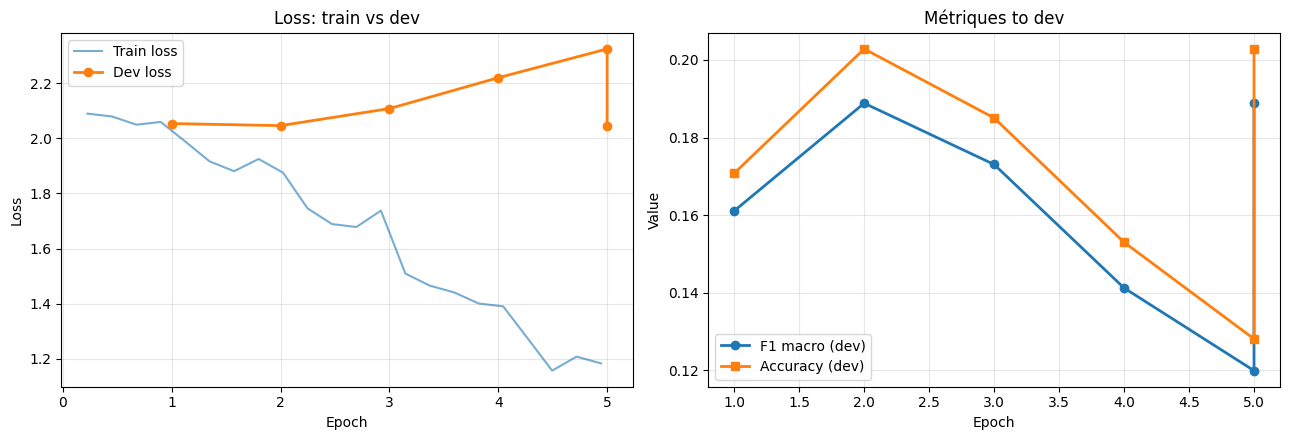

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

history = pd.DataFrame(trainer.state.log_history)

train_log = history[history['loss'].notna()][['epoch', 'loss']]
eval_log  = history[history['eval_loss'].notna()][['epoch', 'eval_loss', 'eval_accuracy', 'eval_f1_macro']]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Graphique 1: loss ---
axes[0].plot(train_log['epoch'], train_log['loss'], label='Train loss', alpha=0.6)
axes[0].plot(eval_log['epoch'], eval_log['eval_loss'], 'o-', label='Dev loss', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss: train vs dev')
axes[0].legend()
axes[0].grid(alpha=0.3)

# --- Graphique 2: metriques to dev ---
axes[1].plot(eval_log['epoch'], eval_log['eval_f1_macro'], 'o-', label='F1 macro (dev)', linewidth=2)
axes[1].plot(eval_log['epoch'], eval_log['eval_accuracy'], 's-', label='Accuracy (dev)', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Value')
axes[1].set_title('Métriques to dev')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Verifications

In [10]:
out = trainer.predict(test_text_tok)
probs = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()
y = out.label_ids
preds = probs.argmax(1)

# a) Le modèle capte-t-il la valence (positif / négatif) ?
pos = [label2id[e] for e in ['amusement', 'awe', 'contentment', 'excitement']]
y_val, p_val = np.isin(y, pos), np.isin(preds, pos)
print('Accuracy valence :', (y_val == p_val).mean(),
      '| baseline majoritaire :', max(y_val.mean(), 1 - y_val.mean()))

# b) Top-k : la vraie émotion est-elle parmi les k plus probables ?
for k in (1, 2, 3):
    topk = np.argsort(-probs, axis=1)[:, :k]
    print(f'Top-{k} :', np.mean([y[i] in topk[i] for i in range(len(y))]))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Accuracy valence : 0.6070038910505836 | baseline majoritaire : 0.6147859922178989
Top-1 : 0.23346303501945526
Top-2 : 0.36186770428015563
Top-3 : 0.4785992217898833


In [11]:
# ===== Export des probabilités texte pour la fusion (clips AVEC texte uniquement) =====
from sklearn.metrics import f1_score
import torch

OUT = Path('/content/drive/MyDrive/Projet Multimedia/fusion/fusion_txt')
OUT.mkdir(parents=True, exist_ok=True)

def predict_split(split_name):
    """Prédit les probabilités des 8 émotions pour les clips avec texte d'un split."""
    sub = df[(df['split'] == split_name) & df['has_text']].reset_index(drop=True)
    ds = Dataset.from_pandas(sub[['transcript', 'label']]).map(
        tokenize_fn, batched=True, remove_columns=['transcript'])

    out = trainer.predict(ds)                         # l'ordre des prédictions suit celui de `sub`
    probs = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()

    res = pd.DataFrame(probs, columns=EMOTION_LABELS)  # 8 colonnes, une par émotion
    res.insert(0, 'video_id', sub['video_id'].values)  # identifiant du clip
    res.insert(1, 'split', split_name)

    f1 = f1_score(out.label_ids, probs.argmax(1), average='macro')
    print(f"{split_name} : {len(res)} clips avec texte  (F1 macro = {f1:.3f})")
    return res

res_dev  = predict_split('dev')
res_test = predict_split('test')

# --- Un seul CSV (dev + test), sans aucun clip vide ---
res_all = pd.concat([res_dev, res_test], ignore_index=True)

# Vérifications
assert res_all['video_id'].is_unique, "video_id en double"
assert not res_all[EMOTION_LABELS].isna().any().any(), "NaN dans les probabilités"
assert np.allclose(res_all[EMOTION_LABELS].sum(axis=1), 1, atol=1e-4), "les probabilités ne somment pas à 1"
assert set(res_all['video_id']) <= set(df[df['has_text']]['video_id']), "clip sans texte présent dans le CSV"

path_all = OUT / 'probs_transcription.csv'
res_all.to_csv(path_all, index=False)

# Fichiers séparés par split, au cas où le notebook de fusion les attende ainsi
res_dev.drop(columns='split').to_csv(OUT / 'probs_transcription_dev.csv', index=False)
res_test.drop(columns='split').to_csv(OUT / 'probs_transcription_test.csv', index=False)

print(f"\nCSV final : {path_all}  {res_all.shape}")
print(res_all['split'].value_counts().to_string())
res_all.head()

Map:   0%|          | 0/281 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


dev : 281 clips avec texte  (F1 macro = 0.189)


Map:   0%|          | 0/257 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


test : 257 clips avec texte  (F1 macro = 0.209)

CSV final : /content/drive/MyDrive/Projet Multimedia/fusion/fusion_txt/probs_transcription.csv  (538, 10)
split
dev     281
test    257


,video_id,split,amusement,awe,contentment,excitement,anger,disgust,fear,sadness
0,00015_clip_001,dev,0.127546,0.146452,0.257715,0.112905,0.083444,0.085506,0.053727,0.132706
1,00015_clip_004,dev,0.139204,0.042397,0.040949,0.068985,0.107268,0.056310,0.492019,0.052869
2,00015_clip_007,dev,0.151514,0.124025,0.195203,0.063766,0.081504,0.146485,0.136507,0.100996
3,00015_clip_011,dev,0.077276,0.048312,0.030775,0.109626,0.217784,0.068939,0.351173,0.096116
4,00015_clip_013,dev,0.153410,0.153471,0.212425,0.071089,0.074647,0.091876,0.110559,0.132523


In [12]:
# ===== Export des probabilités texte pour la fusion (clips AVEC texte uniquement) =====
from sklearn.metrics import f1_score
from google.colab import files
import torch

# Dossier local de Colab (pas de Drive) : les fichiers sont ensuite téléchargés sur l'ordinateur
OUT = Path('/content/probs_texte')
OUT.mkdir(parents=True, exist_ok=True)

def predict_split(split_name):
    """Prédit les probabilités des 8 émotions pour les clips avec texte d'un split."""
    sub = df[(df['split'] == split_name) & df['has_text']].reset_index(drop=True)
    ds = Dataset.from_pandas(sub[['transcript', 'label']]).map(
        tokenize_fn, batched=True, remove_columns=['transcript'])

    out = trainer.predict(ds)                         # l'ordre des prédictions suit celui de `sub`
    probs = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()

    res = pd.DataFrame(probs, columns=EMOTION_LABELS)  # 8 colonnes, une par émotion
    res.insert(0, 'video_id', sub['video_id'].values)  # identifiant du clip
    res.insert(1, 'split', split_name)

    f1 = f1_score(out.label_ids, probs.argmax(1), average='macro')
    print(f"{split_name} : {len(res)} clips avec texte  (F1 macro = {f1:.3f})")
    return res

res_dev  = predict_split('dev')
res_test = predict_split('test')

# --- Un seul CSV (dev + test), sans aucun clip vide ---
res_all = pd.concat([res_dev, res_test], ignore_index=True)

# Vérifications
assert res_all['video_id'].is_unique, "video_id en double"
assert not res_all[EMOTION_LABELS].isna().any().any(), "NaN dans les probabilités"
assert np.allclose(res_all[EMOTION_LABELS].sum(axis=1), 1, atol=1e-4), "les probabilités ne somment pas à 1"
assert set(res_all['video_id']) <= set(df[df['has_text']]['video_id']), "clip sans texte présent dans le CSV"

path_all = OUT / 'probs_transcription.csv'
res_all.to_csv(path_all, index=False)

# Fichiers séparés par split, au cas où le notebook de fusion les attende ainsi
path_dev  = OUT / 'probs_transcription_dev.csv'
path_test = OUT / 'probs_transcription_test.csv'
res_dev.drop(columns='split').to_csv(path_dev, index=False)
res_test.drop(columns='split').to_csv(path_test, index=False)

print(f"\nCSV final : {path_all}  {res_all.shape}")
print(res_all['split'].value_counts().to_string())

# --- Téléchargement sur l'ordinateur ---
files.download(str(path_all))
files.download(str(path_dev))
files.download(str(path_test))

Map:   0%|          | 0/281 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


dev : 281 clips avec texte  (F1 macro = 0.189)


Map:   0%|          | 0/257 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


test : 257 clips avec texte  (F1 macro = 0.209)

CSV final : /content/probs_texte/probs_transcription.csv  (538, 10)
split
dev     281
test    257


... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>